# Subscription renewals, retention cohorts and segmentation

FormWise is a made-up online legal-document subscription service. The data is simulated (see `data/generate_data.py`).

Questions:
1. How well do monthly subscribers renew, and when do we lose them?
2. What early behaviour predicts renewal?
3. Which customer groups matter most, and what should we do for each?

Data runs to Sep 30, 2026. A monthly subscriber counts as retained in month k if they paid for month k. I only
count months that have fully passed for each subscriber, so recent signups aren't treated as churned just because
their renewal date hasn't come yet.

In [1]:
import os, sys, sqlite3, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DB = "data/formwise.db"
if not os.path.exists(DB):
    subprocess.run([sys.executable, "data/generate_data.py"], check=True)
con = sqlite3.connect(DB)

def q(sql):
    if sql.endswith(".sql"):
        sql = open(sql).read()
    return pd.read_sql_query(sql, con)

BLUE, ORANGE, GREY = "#2B5C8A", "#D9822B", "#9AA5B1"
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
os.makedirs("figures", exist_ok=True)
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

AS_OF = pd.Timestamp("2026-09-30")
subs = q("""
SELECT s.user_id, s.plan, s.start_ts, s.end_ts, s.payments_made, s.docs_created_30d,
       v.device, v.channel, v.country, v.landing_doc_type
FROM subscriptions s JOIN visitors v ON v.visitor_id = s.visitor_id
""")
subs["start_ts"] = pd.to_datetime(subs.start_ts); subs["end_ts"] = pd.to_datetime(subs.end_ts)
subs["cohort"] = subs.start_ts.dt.to_period("M")
print(subs.plan.value_counts().to_string())

plan
monthly    5256
annual     3327


## 1. Monthly plan retention by cohort

In [2]:
mon = subs[subs.plan == "monthly"].copy()
mon["months_observable"] = ((AS_OF.year - mon.start_ts.dt.year) * 12 + (AS_OF.month - mon.start_ts.dt.month)
                            - (AS_OF.day < mon.start_ts.dt.day)).clip(lower=0)
rows = []
for k in range(0, 13):
    elig = mon[mon.months_observable >= k]
    rows.append(elig.groupby("cohort").apply(lambda d: (d.payments_made > k).mean(), include_groups=False).rename(k))
cohort = pd.concat(rows, axis=1)
print("% of each cohort still paying k months after signup:")
print((cohort.iloc[:, :7] * 100).round(0).to_string())

% of each cohort still paying k months after signup:
             0     1     2     3     4     5     6
cohort                                            
2025-01  100.0  64.0  55.0  48.0  42.0  38.0  35.0
2025-02  100.0  66.0  56.0  49.0  43.0  38.0  37.0
2025-03  100.0  65.0  53.0  44.0  38.0  34.0  28.0
2025-04  100.0  66.0  56.0  46.0  40.0  37.0  34.0
2025-05  100.0  58.0  49.0  44.0  40.0  37.0  33.0
2025-06  100.0  60.0  51.0  46.0  42.0  39.0  37.0
2025-07  100.0  66.0  56.0  49.0  45.0  40.0  36.0
2025-08  100.0  65.0  55.0  45.0  41.0  37.0  35.0
2025-09  100.0  66.0  52.0  44.0  39.0  35.0  32.0
2025-10  100.0  70.0  58.0  51.0  44.0  39.0  37.0
2025-11  100.0  61.0  51.0  44.0  41.0  38.0  35.0
2025-12  100.0  67.0  56.0  50.0  42.0  40.0  35.0
2026-01  100.0  67.0  58.0  51.0  43.0  40.0  35.0
2026-02  100.0  63.0  50.0  44.0  37.0  33.0  31.0
2026-03  100.0  67.0  57.0  48.0  41.0  37.0  33.0
2026-04  100.0  63.0  54.0  47.0  41.0  37.0   NaN
2026-05  100.0  65.0  55.0  4

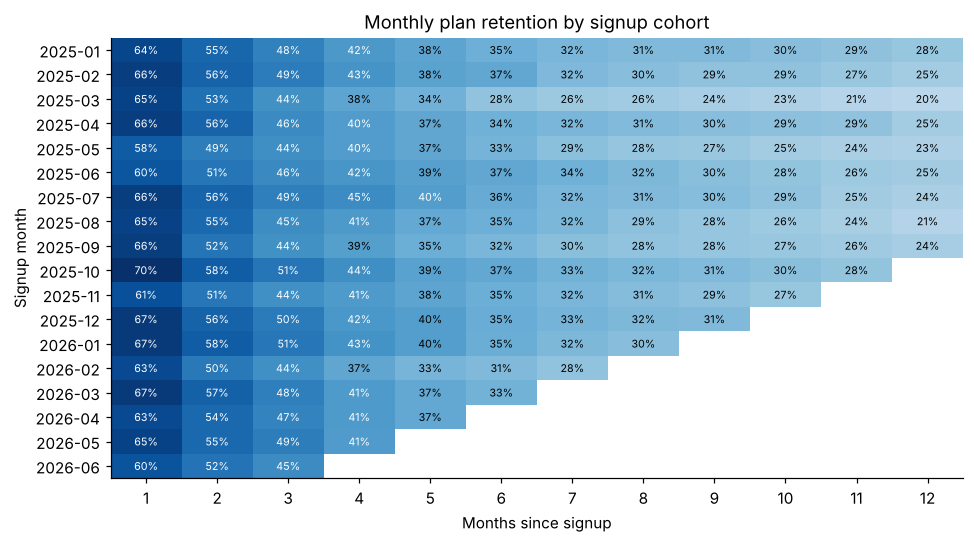

In [3]:
fig, ax = plt.subplots(figsize=(10, 5.2))
data = cohort.iloc[:, 1:13].values
ax.imshow(data, cmap="Blues", vmin=0, vmax=0.7, aspect="auto")
ax.set_xticks(range(data.shape[1]), [str(c) for c in cohort.columns[1:13]])
ax.set_yticks(range(len(cohort)), [str(c) for c in cohort.index])
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        if not np.isnan(data[i, j]):
            ax.text(j, i, f"{data[i,j]:.0%}", ha="center", va="center", fontsize=7,
                    color="white" if data[i, j] > 0.4 else "black")
ax.set_xlabel("Months since signup"); ax.set_ylabel("Signup month"); ax.grid(False)
ax.set_title("Monthly plan retention by signup cohort")
fig.savefig("figures/cohort_heatmap.png", bbox_inches="tight", dpi=140); plt.show()

In [4]:
curve = pd.Series({k: (mon[mon.months_observable >= k].payments_made > k).mean() for k in range(0, 13)})
print("Retention curve, all monthly subscribers:")
print((curve * 100).round(1).to_string())
print(f"\nBiggest drop is before the first renewal: {1-curve[1]:.0%} gone by month 1.")

Retention curve, all monthly subscribers:
0     100.0
1      64.5
2      54.1
3      47.0
4      41.3
5      37.4
6      34.2
7      31.4
8      30.1
9      29.1
10     27.6
11     25.8
12     23.9

Biggest drop is before the first renewal: 35% gone by month 1.


Cohorts look pretty similar, so nothing recent seems to have broken. Most of the loss happens before the first
renewal: lots of people subscribe for one document and leave. After about month 3 the curve flattens out. So the
first 30 days matter most.

## 2. Annual plan renewals

In [5]:
ann = subs[(subs.plan == "annual") & (subs.start_ts + pd.DateOffset(years=1) <= AS_OF)].copy()
ann["renewed"] = ann.payments_made >= 2
ann["engaged"] = np.where(ann.docs_created_30d >= 2, "2+ docs in first 30 days", "0-1 docs in first 30 days")
print(f"Annual subscribers past their renewal date: {len(ann):,}")
print(f"Annual renewal rate: {ann.renewed.mean():.1%}")
print(ann.groupby("engaged").renewed.agg(["mean", "count"]).round(3).to_string())

Annual subscribers past their renewal date: 1,448
Annual renewal rate: 55.3%
                            mean  count
engaged                                
0-1 docs in first 30 days  0.379    393
2+ docs in first 30 days   0.618   1055


## 3. What predicts a monthly subscriber's first renewal?
Logistic regression on monthly subscribers whose first renewal date has passed, reported as odds ratios.
This is correlation, not cause. Engaged users might be different in ways the data doesn't show.

In [6]:
m1 = mon[mon.months_observable >= 1].copy()
m1["renewed_once"] = (m1.payments_made >= 2).astype(int)
m1["engaged"] = (m1.docs_created_30d >= 2).astype(int)
model = smf.logit("renewed_once ~ engaged + C(device, Treatment('desktop')) + C(channel, Treatment('organic_search'))",
                  data=m1).fit(disp=False)
summary = pd.DataFrame({"odds_ratio": np.exp(model.params), "p_value": model.pvalues,
                        "ci_low": np.exp(model.conf_int()[0]), "ci_high": np.exp(model.conf_int()[1])}).drop("Intercept")
summary.index = summary.index.str.replace(r"C\((\w+), Treatment\('\w+'\)\)\[T\.", r"\1=", regex=True).str.rstrip("]")
print(summary.round(3).to_string())
print(f"\nFirst renewal rate: engaged {m1[m1.engaged==1].renewed_once.mean():.1%}, "
      f"not engaged {m1[m1.engaged==0].renewed_once.mean():.1%}  (n={len(m1):,})")

                     odds_ratio  p_value  ci_low  ci_high
device=mobile             0.773    0.000   0.677    0.883
device=tablet             0.905    0.382   0.724    1.132
channel=direct            1.275    0.009   1.062    1.529
channel=email             0.972    0.786   0.789    1.196
channel=paid_search       1.034    0.646   0.895    1.195
channel=referral          0.950    0.720   0.716    1.260
channel=social            1.100    0.423   0.872    1.387
engaged                   2.012    0.000   1.791    2.261

First renewal rate: engaged 72.8%, not engaged 57.1%  (n=5,256)


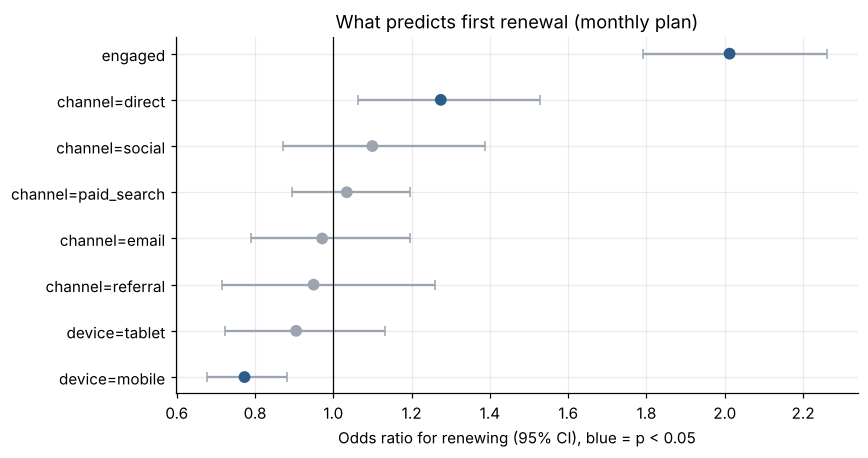

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
s = summary.sort_values("odds_ratio")
ax.errorbar(s.odds_ratio, range(len(s)), xerr=[s.odds_ratio - s.ci_low, s.ci_high - s.odds_ratio],
            fmt="none", ecolor=GREY, capsize=3)
ax.scatter(s.odds_ratio, range(len(s)), color=[BLUE if p < 0.05 else GREY for p in s.p_value], zorder=3, s=45)
ax.axvline(1, color="black", lw=0.8); ax.set_yticks(range(len(s)), s.index)
ax.set_xlabel("Odds ratio for renewing (95% CI), blue = p < 0.05")
ax.set_title("What predicts first renewal (monthly plan)")
fig.savefig("figures/renewal_drivers.png", bbox_inches="tight", dpi=140); plt.show()

Making 2 or more documents in the first 30 days is the strongest signal, roughly doubling the odds of renewing.
Mobile subscribers renew less even when engagement is the same. Channel doesn't matter much once someone has paid.
"Direct" comes in under 0.05, but with seven device and channel terms in the model, one small hit like that could
easily be chance. I wouldn't act on it unless it showed up again.

## 4. Are annual plans really worth more?
The paywall A/B test used "annual plan share shouldn't drop" as a guardrail, because annual subscribers were
assumed to be more valuable. The retention curve lets me check that.

In [8]:
price_m, price_a = 39.99, 95.88
exp_payments_12m = curve.loc[0:11].sum()
rev_m, rev_a = exp_payments_12m * price_m, price_a
print(f"Expected payments in year one per new monthly subscriber: {exp_payments_12m:.2f}")
print(f"Expected first-year revenue: monthly ${rev_m:,.2f} vs annual ${rev_a:,.2f}  ({rev_m/rev_a:.1f}x)")
print(f"Annual over two years including renewals: ${price_a * (1 + ann.renewed.mean()):,.2f}")

Expected payments in year one per new monthly subscriber: 5.23
Expected first-year revenue: monthly $209.01 vs annual $95.88  (2.2x)
Annual over two years including renewals: $148.92


It doesn't hold at current prices. Annual subscribers are more engaged and stick around longer, but the annual
price is only about 2.4 months of the monthly plan. A typical monthly subscriber pays for 5+ months in the first
year, so a monthly signup brings in about twice as much in year one.

So:
- Paywall tests should use expected 12-month revenue per viewer as the guardrail, not annual share. Pushing people
  toward annual could actually lose money.
- Annual pricing is worth raising with product and finance. The discount may be bigger than it needs to be.

## 5. Customer segments (k-means)

In [9]:
ltv = q("SELECT user_id, SUM(amount) AS lifetime_revenue FROM payments GROUP BY user_id")
seg = subs.merge(ltv, on="user_id")
seg["tenure_months"] = ((seg.end_ts.fillna(AS_OF) - seg.start_ts).dt.days / 30.44).round(1)
seg["active"] = seg.end_ts.isna().astype(int)
seg["is_annual"] = (seg.plan == "annual").astype(int)
features = ["tenure_months", "payments_made", "docs_created_30d", "lifetime_revenue", "is_annual"]
X = StandardScaler().fit_transform(seg[features])
scores = {k: silhouette_score(X, KMeans(k, n_init=10, random_state=0).fit_predict(X), sample_size=4000, random_state=0)
          for k in range(3, 7)}
print("Silhouette by k:", {k: round(v, 3) for k, v in scores.items()})
k_best = max(scores, key=scores.get)
seg["cluster"] = KMeans(k_best, n_init=10, random_state=0).fit_predict(X)
profile = seg.groupby("cluster").agg(customers=("user_id", "count"), annual_share=("is_annual", "mean"),
                                     avg_tenure_months=("tenure_months", "mean"), avg_docs_30d=("docs_created_30d", "mean"),
                                     avg_lifetime_revenue=("lifetime_revenue", "mean"), still_active=("active", "mean"),
                                     mobile_share=("device", lambda d: (d == "mobile").mean()))
profile["revenue_share"] = seg.groupby("cluster").lifetime_revenue.sum() / seg.lifetime_revenue.sum()
print(f"\nk = {k_best}")
print(profile.round(2).sort_values("avg_lifetime_revenue", ascending=False).to_string())

Silhouette by k: {3: 0.493, 4: 0.444, 5: 0.422, 6: 0.408}

k = 3
         customers  annual_share  avg_tenure_months  avg_docs_30d  avg_lifetime_revenue  still_active  mobile_share  revenue_share
cluster                                                                                                                           
0             1195           0.0              12.33          1.85                510.77          0.76          0.23           0.43
1             3329           1.0              10.34          2.62                118.99          0.81          0.18           0.28
2             4059           0.0               2.56          1.47                105.70          0.15          0.25           0.30


Naming the clusters from their profiles (done in code so the names stay right if the clustering is re-run):

In [10]:
def name(r):
    if r.annual_share > 0.5:
        return "Annual planners" if r.still_active > 0.5 else "Lapsed annual"
    if r.avg_tenure_months >= 6:
        return "Loyal monthly"
    return "One-and-done" if r.avg_docs_30d < 2 else "Short-term multi-doc"
profile["segment"] = profile.apply(name, axis=1)
summary_seg = profile.groupby("segment").agg(customers=("customers", "sum"), revenue_share=("revenue_share", "sum"),
                                            avg_lifetime_revenue=("avg_lifetime_revenue", "mean"),
                                            still_active=("still_active", "mean"), avg_docs_30d=("avg_docs_30d", "mean"))
summary_seg["customer_share"] = summary_seg.customers / summary_seg.customers.sum()
print(summary_seg.sort_values("revenue_share", ascending=False).round(3).to_string())

                 customers  revenue_share  avg_lifetime_revenue  still_active  avg_docs_30d  customer_share
segment                                                                                                    
Loyal monthly         1195          0.425               510.768         0.763         1.854           0.139
One-and-done          4059          0.299               105.704         0.145         1.470           0.473
Annual planners       3329          0.276               118.988         0.805         2.620           0.388


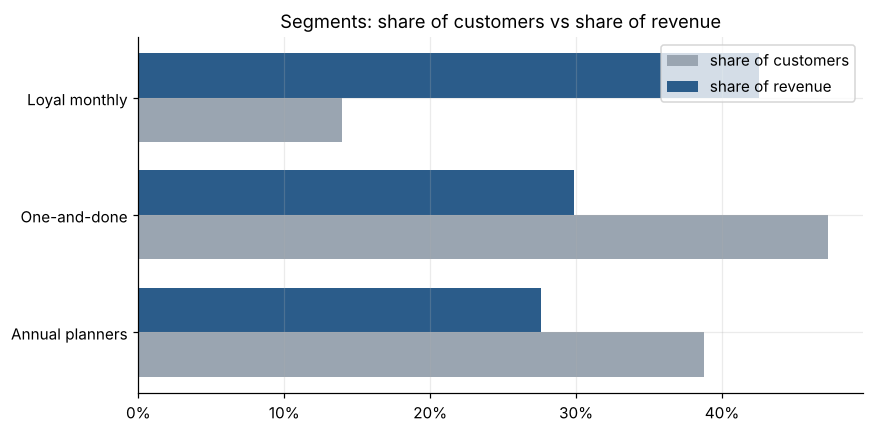

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ss = summary_seg.sort_values("revenue_share")
y = np.arange(len(ss)); h = 0.38
ax.barh(y - h/2, ss.customer_share, h, color=GREY, label="share of customers")
ax.barh(y + h/2, ss.revenue_share, h, color=BLUE, label="share of revenue")
ax.set_yticks(y, ss.index); ax.xaxis.set_major_formatter(pct); ax.legend()
ax.set_title("Segments: share of customers vs share of revenue")
fig.savefig("figures/segments.png", bbox_inches="tight", dpi=140); plt.show()

## 6. Recommendations
1. **Focus on the first 30 days.** A second document is the best renewal signal, so test a nudge right after the
   first download that suggests a related document (lease agreement, then notice to vacate). Primary metric: % of
   new subscribers making 2+ documents in 30 days. Secondary: first renewal rate. Since the regression is only
   correlation, the test is what would show the nudge actually causes renewals.
2. **Look after loyal monthly subscribers.** About 14% of customers, but over 40% of lifetime revenue. Flag anyone
   with no new documents in 60 days and test a re-engagement message.
3. **Offer one-and-done users a one-time purchase.** Almost half of subscribers make a document or two and leave
   within a few months. A one-time option might convert better and cut down refund and chargeback requests. Test it
   against the subscription default on 12-month revenue per paywall viewer.
4. **Change the paywall test guardrail** to expected 12-month revenue, and bring annual pricing to the product owner.
5. **Look into mobile retention.** Mobile subscribers renew less at the same engagement level, which lines up with
   the mobile funnel problems found in the funnel analysis.

In [12]:
con.close()